## EDA

In [2]:
import pandas as pd 
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

In [3]:
data = pd.read_csv("Student Mental Health.csv")
data

,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No
...,...,...,...,...,...,...,...,...,...,...,...
96,13/07/2020 19:56:49,Female,21.0,BCS,year 1,3.50 - 4.00,No,No,Yes,No,No
97,13/07/2020 21:21:42,Male,18.0,Engineering,Year 2,3.00 - 3.49,No,Yes,Yes,No,No
98,13/07/2020 21:22:56,Female,19.0,Nursing,Year 3,3.50 - 4.00,Yes,Yes,No,Yes,No
99,13/07/2020 21:23:57,Female,23.0,Pendidikan Islam,year 4,3.50 - 4.00,No,No,No,No,No


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 11 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Timestamp                                     101 non-null    object 
 1   Choose your gender                            101 non-null    object 
 2   Age                                           100 non-null    float64
 3   What is your course?                          101 non-null    object 
 4   Your current year of Study                    101 non-null    object 
 5   What is your CGPA?                            101 non-null    object 
 6   Marital status                                101 non-null    object 
 7   Do you have Depression?                       101 non-null    object 
 8   Do you have Anxiety?                          101 non-null    object 
 9   Do you have Panic attack?                     101 non-null    obj

In [5]:
data.describe()

,Age
count,100.00000
mean,20.53000
std,2.49628
min,18.00000
25%,18.00000
50%,19.00000
75%,23.00000
max,24.00000


In [6]:
# Drop kolom "Timestamp"
data.drop(["Timestamp"],axis=1, inplace=True)
data

,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No
...,...,...,...,...,...,...,...,...,...,...
96,Female,21.0,BCS,year 1,3.50 - 4.00,No,No,Yes,No,No
97,Male,18.0,Engineering,Year 2,3.00 - 3.49,No,Yes,Yes,No,No
98,Female,19.0,Nursing,Year 3,3.50 - 4.00,Yes,Yes,No,Yes,No
99,Female,23.0,Pendidikan Islam,year 4,3.50 - 4.00,No,No,No,No,No


In [7]:
# Impute data hilang dengan rata-rata
age_mean = np.floor(np.mean(data['Age']))
print(f"Rata-rata kolom Age: {age_mean}")

# Masukkan nilai rata-rata ke dalam data hilang
data['Age'].fillna(age_mean, inplace=True)
data.info()

Rata-rata kolom Age: 20.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 10 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Choose your gender                            101 non-null    object 
 1   Age                                           101 non-null    float64
 2   What is your course?                          101 non-null    object 
 3   Your current year of Study                    101 non-null    object 
 4   What is your CGPA?                            101 non-null    object 
 5   Marital status                                101 non-null    object 
 6   Do you have Depression?                       101 non-null    object 
 7   Do you have Anxiety?                          101 non-null    object 
 8   Do you have Panic attack?                     101 non-null    object 
 9   Did you seek any specialist for a treat

C:\Users\Valent Tanda\AppData\Local\Temp\ipykernel_24564\1747877669.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Age'].fillna(age_mean, inplace=True)


In [8]:
# Mencari nilai unik masing-masing kolom
for col in data.columns:
    print(f"Kolom {col} memiliki {data[col].nunique()} nilai unik")
    print(data[col].value_counts())
    print("\n")

Kolom Choose your gender memiliki 2 nilai unik
Choose your gender
Female    75
Male      26
Name: count, dtype: int64


Kolom Age memiliki 7 nilai unik
Age
18.0    32
24.0    23
19.0    21
23.0    13
20.0     7
21.0     3
22.0     2
Name: count, dtype: int64


Kolom What is your course? memiliki 49 nilai unik
What is your course?
BCS                        18
Engineering                17
BIT                        10
KOE                         4
Biomedical science          4
psychology                  2
BENL                        2
Engine                      2
Laws                        2
Irkhs                       1
Psychology                  1
Accounting                  1
KENMS                       1
Mathemathics                1
Pendidikan islam            1
Human Resources             1
Islamic education           1
Business Administration     1
Banking Studies             1
Marine science              1
ENM                         1
TAASL                       1
Usuluddi

In [9]:
# Pisah kolom numerik dan kategorikal
numerical_column = data.select_dtypes(include=[np.number]).columns.tolist()
categorical_column = data.select_dtypes(exclude=[np.number]).columns.tolist()
print("Data Numerik: ", numerical_column)
print("Data Kategorikal: ", categorical_column)

Data Numerik:  ['Age']
Data Kategorikal:  ['Choose your gender', 'What is your course?', 'Your current year of Study', 'What is your CGPA?', 'Marital status', 'Do you have Depression?', 'Do you have Anxiety?', 'Do you have Panic attack?', 'Did you seek any specialist for a treatment?']


In [20]:
data.to_csv("Student Mental health Cleaned.csv", index=False)

## Preprocessing

Binning

In [10]:
preprocessed_data = data.copy()

In [11]:
# Proses binning course
course_binned = {
    'Science and Tech': ['Engineering', 'Mathemathics', 'BIT', 'Marine science', 'KOE', 'Engine', 'Biomedical science', 'IT', 'CTS', 'engin', 'Biotechnology', 'koe', 'Koe'],
    'Nursery': ['MHSC', 'Kop', 'Radiography', 'Nursing ', 'Diploma Nursing'],
    'Social': ['BCS', 'Human Resources', 'Psychology', 'KENMS', 'Accounting ', 'ENM', 'Banking Studies', 'Business Administration',  'Econs', 'Malcom', 'Human Sciences ', 'Communication ', 'psychology'],
    'Islamic Study': ['Islamic education', 'Islamic Education', 'Pendidikan islam', 'Irkhs', 'KIRKHS', 'Kirkhs', 'Usuluddin ', 'ALA', 'Pendidikan Islam', 'Fiqh', 'Fiqh fatwa ', 'Pendidikan Islam '],
    'Language': ['BENL', 'TAASL', 'DIPLOMA TESL', 'Benl'],
    'Law': ['Laws', 'Law']
}

# Proses binning year
year_binned = {
  'Year 1' : ['year 1', 'Year 1'],
  'Year 2' : ['year 2', 'Year 2'],
  'Year 3' : ['year 3', 'Year 3'],
	'Year 4' : ['year 4', 'Year 4']
}

cgpa_binned = {
  '3.50 - 4.00' : ['3.50 - 4.00', '3.50-4.00 '],
  '3.00 - 3.49' : ['3.00 - 3.49'],
  '2.50 - 2.99' : ['2.50 - 2.99'],
	'2.00 - 2.49' : ['2.00 - 2.49'],
	'0 - 1.99' : ['0 - 1.99']
}

# Apply binning to the 'What is your course?' column
preprocessed_data['What is your course?'] = preprocessed_data['What is your course?'].apply(lambda x: next((key for key, values in course_binned.items() if x in values), 'Other'))
preprocessed_data['Your current year of Study'] = preprocessed_data['Your current year of Study'].apply(lambda x: next((key for key, values in year_binned.items() if x in values), 'Other'))
preprocessed_data['What is your CGPA?'] = preprocessed_data['What is your CGPA?'].apply(lambda x: next((key for key, values in cgpa_binned.items() if x in values), 'Other'))
preprocessed_data

,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,Female,18.0,Science and Tech,Year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,Male,21.0,Islamic Study,Year 2,3.00 - 3.49,No,No,Yes,No,No
2,Male,19.0,Science and Tech,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,Female,22.0,Law,Year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,Male,23.0,Science and Tech,Year 4,3.00 - 3.49,No,No,No,No,No
...,...,...,...,...,...,...,...,...,...,...
96,Female,21.0,Social,Year 1,3.50 - 4.00,No,No,Yes,No,No
97,Male,18.0,Science and Tech,Year 2,3.00 - 3.49,No,Yes,Yes,No,No
98,Female,19.0,Nursery,Year 3,3.50 - 4.00,Yes,Yes,No,Yes,No
99,Female,23.0,Islamic Study,Year 4,3.50 - 4.00,No,No,No,No,No



Encoding

In [12]:
# Label Encoding
cgpa_mapping = {
	"3.50 - 4.00": 0,
	"3.00 - 3.49": 1,
	"2.50 - 2.99": 2,
	"2.00 - 2.49": 3,
	"0 - 1.99": 4,
}

# Class label encoding
class LabelEncoder:
	def __init__(self):
		self.gender_mapping = {}
		self.study_mapping = {}
		self.marital_mapping = {}
		self.depression_mapping = {}
		self.anxiety_mapping = {}
		self.panic_attack_mapping = {}
		self.treatment_mapping = {}	
		self.course_mapping = {}

	def fit(self, preprocessed_data):
		self.gender_mapping = {g: i for i, g in enumerate(preprocessed_data['Choose your gender'].unique())}
		self.study_mapping = {s: i for i, s in enumerate(preprocessed_data['Your current year of Study'].unique())}
		self.marital_mapping = {m: i for i, m in enumerate(preprocessed_data['Marital status'].unique())}
		self.depression_mapping = {d: i for i, d in enumerate(preprocessed_data['Do you have Depression?'].unique())}
		self.anxiety_mapping = {a: i for i, a in enumerate(preprocessed_data['Do you have Anxiety?'].unique())}	
		self.panic_attack_mapping = {p: i for i, p in enumerate(preprocessed_data['Do you have Panic attack?'].unique())}
		self.treatment_mapping = {t: i for i, t in enumerate(preprocessed_data['Did you seek any specialist for a treatment?'].unique())}
		self.course_mapping = {c: i for i, c in enumerate(preprocessed_data['What is your course?'].unique())}
	
	def transform(self, preprocessed_data):
		preprocessed_data['Choose your gender'] = preprocessed_data['Choose your gender'].map(self.gender_mapping).astype('Int64')
		preprocessed_data['Your current year of Study'] = preprocessed_data['Your current year of Study'].map(self.study_mapping).astype('Int64')
		preprocessed_data['Marital status'] = preprocessed_data['Marital status'].map(self.marital_mapping).astype('Int64')
		preprocessed_data['Do you have Depression?'] = preprocessed_data['Do you have Depression?'].map(self.depression_mapping).astype('Int64')	
		preprocessed_data['Do you have Anxiety?'] = preprocessed_data['Do you have Anxiety?'].map(self.anxiety_mapping).astype('Int64')
		preprocessed_data['Do you have Panic attack?'] = preprocessed_data['Do you have Panic attack?'].map(self.panic_attack_mapping).astype('Int64')	
		preprocessed_data['Did you seek any specialist for a treatment?'] = preprocessed_data['Did you seek any specialist for a treatment?'].map(self.treatment_mapping).astype('Int64')
		preprocessed_data['What is your course?'] = preprocessed_data['What is your course?'].map(self.course_mapping).astype('Int64')
		return preprocessed_data
   
	def fit_transform(self, preprocessed_data):
		self.fit(preprocessed_data)
		return self.transform(preprocessed_data)

label_encoder = LabelEncoder()
preprocessed_data['What is your CGPA?'] = preprocessed_data['What is your CGPA?'].map(cgpa_mapping)
encoded_data = preprocessed_data.copy()
encoded_data = label_encoder.fit_transform(encoded_data)
encoded_data

,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,0,18.0,0,0,1.0,0,0,0,0,0
1,1,21.0,1,1,1.0,0,1,1,1,0
2,1,19.0,0,0,1.0,0,0,1,0,0
3,0,22.0,2,2,1.0,1,0,0,1,0
4,1,23.0,0,3,1.0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...
96,0,21.0,3,0,0.0,0,1,1,1,0
97,1,18.0,0,1,1.0,0,0,1,1,0
98,0,19.0,5,2,0.0,1,0,0,0,0
99,0,23.0,1,3,0.0,0,1,0,1,0


Normalisasi

In [13]:
normalized_data = encoded_data.copy()
norm_col = []
for col in normalized_data.columns:
  if normalized_data[col].nunique() > 2:
    norm_col.append(col)
print(norm_col)

['Age', 'What is your course?', 'Your current year of Study', 'What is your CGPA?']


In [14]:
minmax = {}
for col in norm_col:
  min_val = normalized_data[col].min()
  max_val = normalized_data[col].max()
  
  minmax[col] = {"Min": min_val, "Max": max_val}
  
  normalized_data[col] = (normalized_data[col] - min_val) / (max_val - min_val)
normalized_data 

,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,0,0.000000,0.0,0.0,0.25,0,0,0,0,0
1,1,0.500000,0.2,0.333333,0.25,0,1,1,1,0
2,1,0.166667,0.0,0.0,0.25,0,0,1,0,0
3,0,0.666667,0.4,0.666667,0.25,1,0,0,1,0
4,1,0.833333,0.0,1.0,0.25,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...
96,0,0.500000,0.6,0.0,0.00,0,1,1,1,0
97,1,0.000000,0.0,0.333333,0.25,0,0,1,1,0
98,0,0.166667,1.0,0.666667,0.00,1,0,0,0,0
99,0,0.833333,0.2,1.0,0.00,0,1,0,1,0


In [15]:
normalized_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 10 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Choose your gender                            101 non-null    Int64  
 1   Age                                           101 non-null    float64
 2   What is your course?                          101 non-null    Float64
 3   Your current year of Study                    101 non-null    Float64
 4   What is your CGPA?                            100 non-null    float64
 5   Marital status                                101 non-null    Int64  
 6   Do you have Depression?                       101 non-null    Int64  
 7   Do you have Anxiety?                          101 non-null    Int64  
 8   Do you have Panic attack?                     101 non-null    Int64  
 9   Did you seek any specialist for a treatment?  101 non-null    Int

In [16]:
normalized_data = normalized_data.dropna()
normalized_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 0 to 100
Data columns (total 10 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Choose your gender                            100 non-null    Int64  
 1   Age                                           100 non-null    float64
 2   What is your course?                          100 non-null    Float64
 3   Your current year of Study                    100 non-null    Float64
 4   What is your CGPA?                            100 non-null    float64
 5   Marital status                                100 non-null    Int64  
 6   Do you have Depression?                       100 non-null    Int64  
 7   Do you have Anxiety?                          100 non-null    Int64  
 8   Do you have Panic attack?                     100 non-null    Int64  
 9   Did you seek any specialist for a treatment?  100 non-null    Int64  


In [17]:
normalized_data.to_csv('preprocessed_data.csv', index=False)

## Modeling

AHC Single Linkage

In [18]:
def euclidean(p1, p2):
    """Menghitung jarak Euclidean antar 2 titik"""
    return np.sqrt(np.sum((p1 - p2) ** 2))

def cluster_distance(c1, c2, data):
    """Menghitung jarak antar 2 cluster (single linkage)"""
    return min(euclidean(data[i], data[j]) for i in c1 for j in c2)

def silhouette_score(X, labels):
    """Menghitung nilai silhouette score untuk label clustering"""
    n = len(X)
    unique_labels = np.unique(labels)
    silhouette_scores = []
    for i in range(n):
        same_cluster = labels[i]
        other_clusters = [label for label in unique_labels if label != same_cluster]

        a = np.mean([
            euclidean(X[i], X[j])
            for j in range(n)
            if labels[j] == same_cluster and i != j
        ]) if np.sum(labels == same_cluster) > 1 else 0

        b = np.inf
        for other in other_clusters:
            distances = [
                euclidean(X[i], X[j])
                for j in range(n) if labels[j] == other
            ]
            b = min(b, np.mean(distances))

        s = (b - a) / max(a, b) if max(a, b) > 0 else 0
        silhouette_scores.append(s)

    return np.mean(silhouette_scores)

def AgglomerativeClustering(X, n_clusters):
    """Menghasilkan labels untuk jumlah cluster tertentu dan linkage matrix lengkap"""
    n = len(X)
    clusters = [[i] for i in range(n)]
    cluster_ids = list(range(n))
    current_id = n
    linkage = []
    cluster_snapshots = None

    while len(clusters) > 1:
        min_dist = float('inf')
        to_merge = (None, None)

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                dist = cluster_distance(clusters[i], clusters[j], X)
                if dist < min_dist:
                    min_dist = dist
                    to_merge = (i, j)

        i, j = to_merge
        ci, cj = clusters[i], clusters[j]
        id_i, id_j = cluster_ids[i], cluster_ids[j]
        new_cluster = ci + cj

        linkage.append([id_i, id_j, min_dist, len(new_cluster)])

        clusters[i] = new_cluster
        cluster_ids[i] = current_id
        current_id += 1
        del clusters[j]
        del cluster_ids[j]

        # Simpan snapshot clustering saat jumlah cluster == n_clusters
        if len(clusters) == n_clusters:
            cluster_snapshots = clusters.copy()

    # Sekarang buat labels dari snapshot
    labels = np.zeros(n, dtype=int)
    for cluster_idx, indices in enumerate(cluster_snapshots):
        for idx in indices:
            labels[idx] = cluster_idx

    score = silhouette_score(X, labels)
    return labels, score, np.array(linkage, dtype=float)


=== Hasil Clustering ===
Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0]
Silhouette Score: 0.198


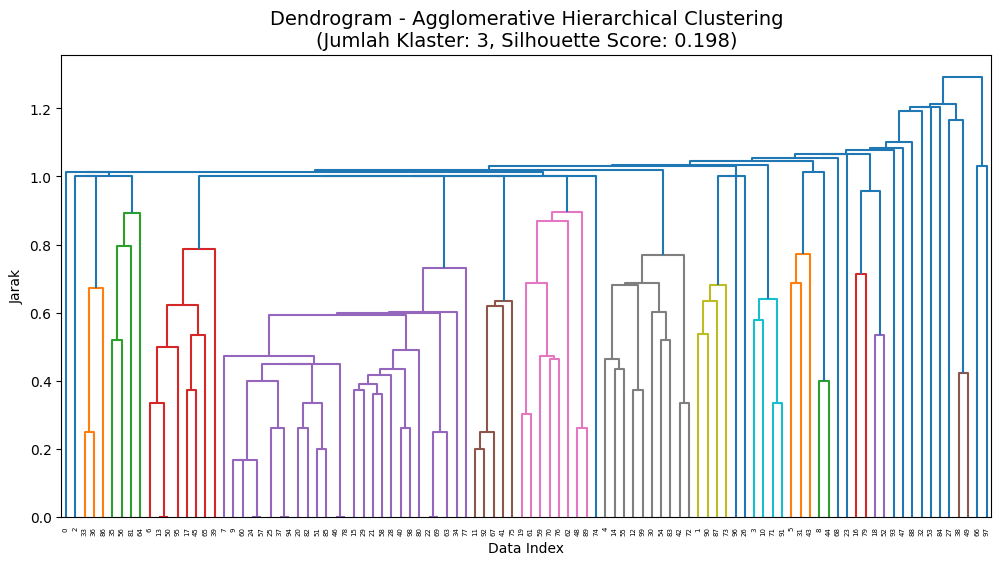

In [19]:
n_clusters = 3
X = np.array(normalized_data)
labels, score, linkage_matrix = AgglomerativeClustering(X, n_clusters)

# ✅ Cetak Hasil
print("\n=== Hasil Clustering ===")
print("Labels:", labels)
print("Silhouette Score:", round(score, 4))

# ✅ Visualisasi Dendrogram
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix)
plt.title(f"Dendrogram - Agglomerative Hierarchical Clustering\n(Jumlah Klaster: {n_clusters}, Silhouette Score: {round(score, 4)})",
           fontsize=14)
plt.xlabel("Data Index")
plt.ylabel("Jarak")
plt.show()